# Online Retail Dataset — Complete EDA, Data Cleaning & Feature Engineering

### Google Colab edition

Run this notebook in **Google Colab**, from top to bottom. The dataset-loading cell uses Colab's built-in upload dialog and reads the uploaded Excel/CSV file directly from memory, so you do not need to set a file path.

This beginner-friendly notebook explores the Online Retail dataset, visualizes data quality and business patterns, applies a documented cleaning policy, and creates the invoice-by-product binary basket matrix for your Apriori cross-sell recommendation engine.

**Important:** the notebook prepares the data; Apriori model training and final evaluation are a later step. Review the cleaning audit because excluding cancellations, returns and zero-price lines is a modelling choice.

## 1. What the dataset columns mean

The classic UCI Online Retail dataset usually contains `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, and `Country`.

- **InvoiceNo:** groups product lines belonging to one invoice.
- **StockCode:** product identifier; use this as the model's canonical product ID.
- **Description:** readable product name for reports and the dashboard.
- **Quantity:** number of units in a product line. Negative quantities may represent returns/corrections.
- **InvoiceDate:** date/time used for trend analysis and chronological evaluation.
- **UnitPrice:** recorded price per unit.
- **CustomerID:** optional customer analysis; missing IDs do not automatically invalidate a basket.
- **Country:** optional geographic analysis.

A row is normally a product line, not necessarily a complete order. The feature-engineering stage turns invoice lines into product baskets.

## 2. Setup and load the dataset

If needed, install dependencies in your terminal:
```bash
pip install pandas numpy matplotlib seaborn openpyxl
```

**How to choose the file:** set `DATA_PATH` to the path of the downloaded Excel or CSV file. If you leave it blank, the notebook will ask you to upload a file when run in Google Colab. In Jupyter, you can instead set the path directly.

In [1]:
from pathlib import Path
import warnings
import json
import sys
import platform
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

# OPTION A: Put your file path here, for example:
# DATA_PATH = "data/raw/Online Retail.xlsx"
# OPTION B: Leave as None to select/upload a file below.
DATA_PATH = None

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Output folder:", OUTPUT_DIR.resolve())

Python: 3.13.16
Pandas: 2.2.3
NumPy: 2.1.3
Output folder: /content/data/processed


In [4]:
import io
import pandas as pd
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError(
        "No file was uploaded. Run this cell again and select your Online Retail Excel or CSV file."
    )

file_name = next(iter(uploaded.keys()))
file_bytes = uploaded[file_name]
file_lower = file_name.lower()

try:
    if file_lower.endswith((".xlsx", ".xls")):
        raw_df = pd.read_excel(io.BytesIO(file_bytes))
    elif file_lower.endswith(".csv"):
        raw_df = pd.read_csv(io.BytesIO(file_bytes), encoding_errors="replace")
    else:
        raise ValueError(
            f"Unsupported file type: {file_name}. Upload a .xlsx, .xls, or .csv file."
        )
except Exception as exc:
    raise RuntimeError(
        f"Could not read '{file_name}'. Confirm it is a valid Excel/CSV dataset. "
        f"Original error: {type(exc).__name__}: {exc}"
    ) from exc

df_raw = raw_df.copy(deep=True)
print(f"File: {file_name}")
print(f"Loaded {len(df_raw):,} rows and {df_raw.shape[1]} columns.")
display(df_raw.head())

Saving online_retail.csv to online_retail.csv
File: online_retail.csv
Loaded 541,909 rows and 8 columns.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom


## 3. Check the schema and standardize column names

Column names sometimes have extra spaces or different capitalization. This cell trims spaces and maps common variants to the expected names. It does not invent missing columns.

In [5]:
df = df_raw.copy(deep=True)
df.columns = [str(c).strip() for c in df.columns]

# Map common column-name variants to the PRD's expected schema.
column_map = {}
for col in df.columns:
    key = col.strip().lower().replace(" ", "").replace("_", "")
    aliases = {
        "invoiceno": "InvoiceNo",
        "stockcode": "StockCode",
        "description": "Description",
        "quantity": "Quantity",
        "invoicedate": "InvoiceDate",
        "unitprice": "UnitPrice",
        "customerid": "CustomerID",
        "country": "Country",
    }
    if key in aliases:
        column_map[col] = aliases[key]
df = df.rename(columns=column_map)

required_for_project = ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "UnitPrice"]
missing_required = [c for c in required_for_project if c not in df.columns]
print("Columns found:", df.columns.tolist())
print("Required columns missing:", missing_required)

if missing_required:
    raise ValueError(
        "This file does not match the expected Online Retail schema. "
        f"Missing: {missing_required}. Check the dataset version or update the column mapping."
    )

# Add optional columns if absent, so later analysis can explain their absence gracefully.
for optional_col in ["Description", "CustomerID", "Country"]:
    if optional_col not in df.columns:
        df[optional_col] = pd.NA
        print(f"Note: '{optional_col}' is absent; created an empty optional column.")

Columns found: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Required columns missing: []


## 4. Initial dataset overview

These checks answer: how large is the dataset, what are the data types, how many invoices/products/customers exist, and what date range is covered?

Invoice and stock codes are identifiers, not measurements. We will preserve them as strings.

In [6]:
overview = pd.DataFrame({
    "Metric": [
        "Rows", "Columns", "Unique invoice IDs (including cancellation IDs)",
        "Unique stock codes", "Unique non-missing customers",
        "Unique countries", "Exact duplicate rows"
    ],
    "Value": [
        len(df), df.shape[1],
        df["InvoiceNo"].nunique(dropna=True),
        df["StockCode"].nunique(dropna=True),
        df["CustomerID"].nunique(dropna=True),
        df["Country"].nunique(dropna=True),
        int(df.duplicated().sum())
    ]
})
display(overview)

print("\nData types and non-null counts:")
df.info()

print("\nFirst rows:")
display(df.head(10))

,Metric,Value
0,Rows,541909
1,Columns,8
2,Unique invoice IDs (including cancellation IDs),25900
3,Unique stock codes,4070
4,Unique non-missing customers,4372
5,Unique countries,38
6,Exact duplicate rows,5268



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

First rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.650,"17,850.000",United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.250,"17,850.000",United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.850,"17,850.000",United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.850,"17,850.000",United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.690,"13,047.000",United Kingdom


## 5. Missing values

We inspect both the count and percentage of missing values. A missing `CustomerID` does not necessarily prevent a row from being used in invoice-level basket mining. Missing invoice or product identifiers are much more serious.

,missing_count,missing_percent
CustomerID,135080,24.930
Description,1454,0.270
StockCode,0,0.000
InvoiceNo,0,0.000
Quantity,0,0.000
InvoiceDate,0,0.000
UnitPrice,0,0.000
Country,0,0.000


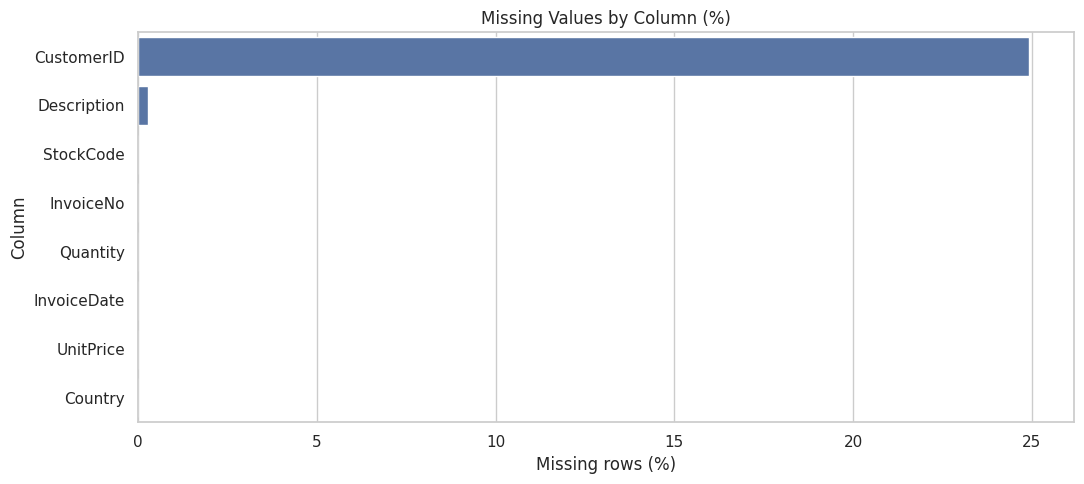

In [7]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=missing_summary.reset_index(),
    x="missing_percent", y="index"
)
plt.title("Missing Values by Column (%)")
plt.xlabel("Missing rows (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

## 6. Convert data types carefully

We parse dates and numeric columns safely. Invoice and stock codes are strings because their numerical value has no mathematical meaning. We preserve a copy before cleaning.

In [8]:
df = df.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df["StockCode"] = df["StockCode"].astype("string").str.strip()
df["Description"] = df["Description"].astype("string").str.strip()
df["Country"] = df["Country"].astype("string").str.strip()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

print(df[["InvoiceNo", "StockCode", "InvoiceDate", "Quantity", "UnitPrice"]].dtypes)
print("Dates that could not be parsed:", int(df["InvoiceDate"].isna().sum()))
print("Quantity values that could not be parsed:", int(df["Quantity"].isna().sum()))
print("UnitPrice values that could not be parsed:", int(df["UnitPrice"].isna().sum()))

InvoiceNo      string[python]
StockCode      string[python]
InvoiceDate    datetime64[ns]
Quantity                int64
UnitPrice             float64
dtype: object
Dates that could not be parsed: 0
Quantity values that could not be parsed: 0
UnitPrice values that could not be parsed: 0


## 7. EDA: quantities and prices

Quantity and unit price often have skewed distributions and outliers. We inspect both the ordinary range and extreme values. Do not automatically delete an outlier merely because it is large; bulk purchases can be legitimate.

,Quantity,UnitPrice
count,"541,909.000","541,909.000"
mean,9.552,4.611
std,218.081,96.760
min,"-80,995.000","-11,062.060"
1%,-2.000,0.190
5%,1.000,0.420
25%,1.000,1.250
50%,3.000,2.080
75%,10.000,4.130
95%,29.000,9.950


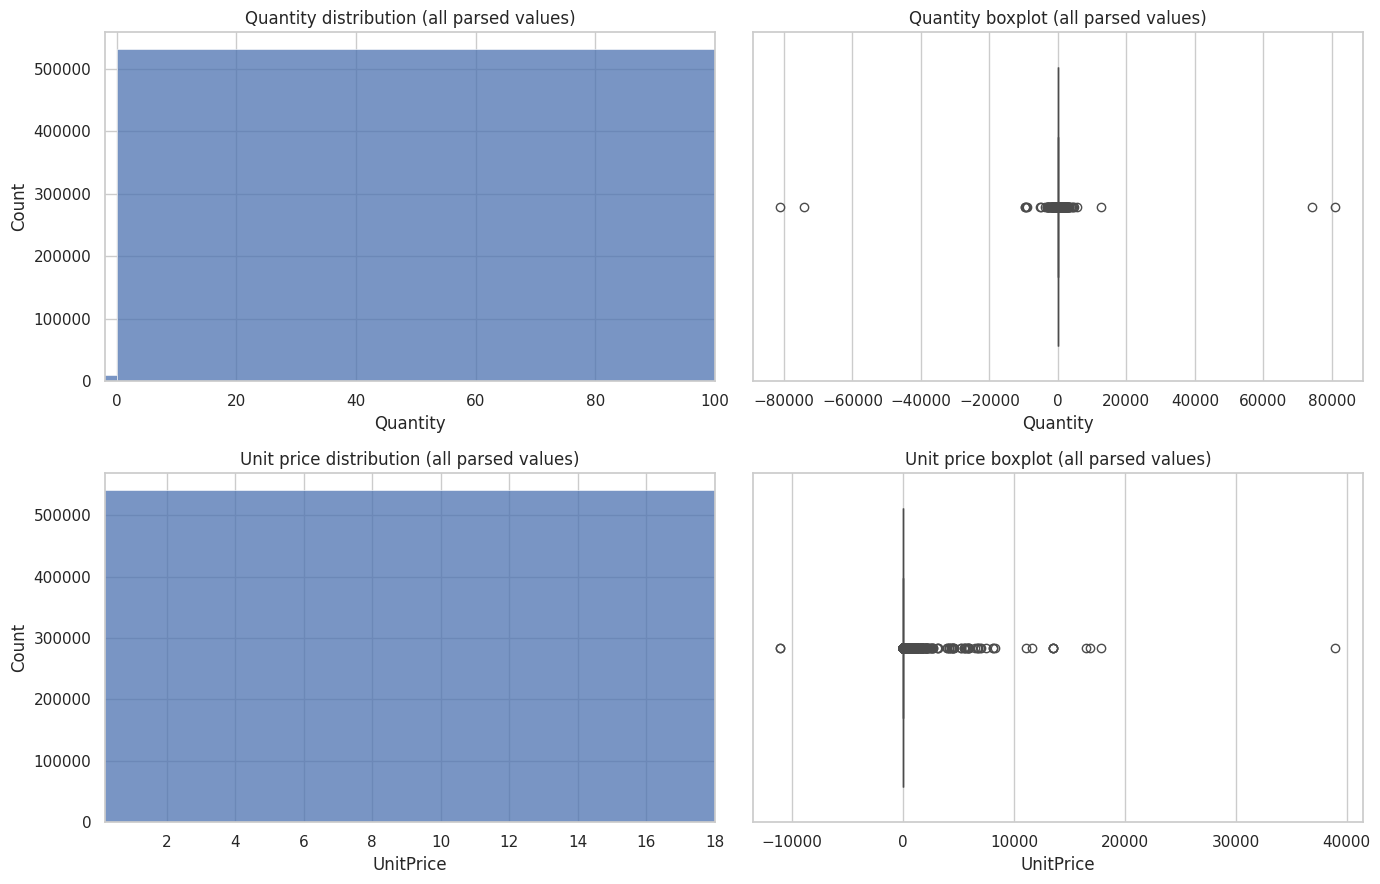

Negative quantity rows: 10624
Zero quantity rows: 0
Negative unit-price rows: 2
Zero unit-price rows: 2515


In [9]:
display(df[["Quantity", "UnitPrice"]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(df["Quantity"].dropna(), bins=80, ax=axes[0, 0])
axes[0, 0].set_title("Quantity distribution (all parsed values)")
axes[0, 0].set_xlim(
    df["Quantity"].quantile(0.01),
    df["Quantity"].quantile(0.99)
)
sns.boxplot(x=df["Quantity"].dropna(), ax=axes[0, 1])
axes[0, 1].set_title("Quantity boxplot (all parsed values)")
sns.histplot(df["UnitPrice"].dropna(), bins=80, ax=axes[1, 0])
axes[1, 0].set_title("Unit price distribution (all parsed values)")
axes[1, 0].set_xlim(
    df["UnitPrice"].quantile(0.01),
    df["UnitPrice"].quantile(0.99)
)
sns.boxplot(x=df["UnitPrice"].dropna(), ax=axes[1, 1])
axes[1, 1].set_title("Unit price boxplot (all parsed values)")
plt.tight_layout()
plt.show()

print("Negative quantity rows:", int((df["Quantity"] < 0).sum()))
print("Zero quantity rows:", int((df["Quantity"] == 0).sum()))
print("Negative unit-price rows:", int((df["UnitPrice"] < 0).sum()))
print("Zero unit-price rows:", int((df["UnitPrice"] == 0).sum()))

## 8. EDA: cancellations, returns and invoice patterns

In the classic UCI dataset, invoice numbers starting with `C` commonly identify cancellations. Negative quantities can indicate returns or corrections. We measure these separately before applying the chosen policy.

,Measure,Count
0,Rows whose invoice starts with C,9288
1,Unique cancellation invoice IDs,3836
2,Rows with negative quantity,10624
3,Rows with zero quantity,0
4,Rows with negative unit price,2
5,Rows with zero unit price,2515


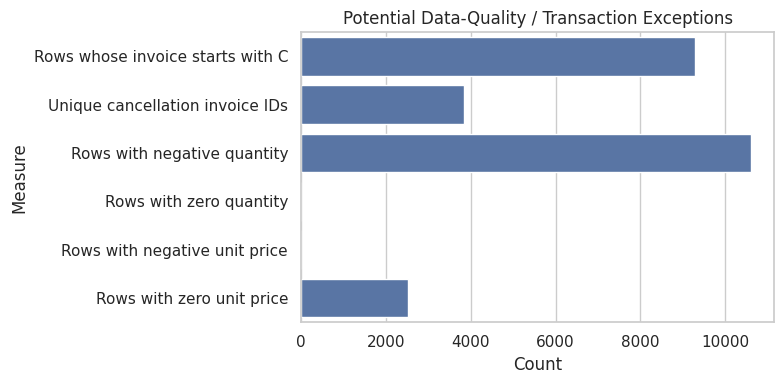

In [10]:
invoice_text = df["InvoiceNo"].astype("string")
is_cancelled = invoice_text.str.upper().str.startswith("C", na=False)

cancellation_summary = pd.DataFrame({
    "Measure": [
        "Rows whose invoice starts with C",
        "Unique cancellation invoice IDs",
        "Rows with negative quantity",
        "Rows with zero quantity",
        "Rows with negative unit price",
        "Rows with zero unit price"
    ],
    "Count": [
        int(is_cancelled.sum()),
        int(df.loc[is_cancelled, "InvoiceNo"].nunique()),
        int((df["Quantity"] < 0).sum()),
        int((df["Quantity"] == 0).sum()),
        int((df["UnitPrice"] < 0).sum()),
        int((df["UnitPrice"] == 0).sum())
    ]
})
display(cancellation_summary)

plt.figure(figsize=(8, 4))
sns.barplot(data=cancellation_summary, x="Count", y="Measure")
plt.title("Potential Data-Quality / Transaction Exceptions")
plt.tight_layout()
plt.show()

## 9. EDA: products, invoices and customers

We distinguish product popularity by invoice count from popularity by quantity. These answer different questions. Invoice count is often more relevant to association mining because Apriori works with product presence in transactions.

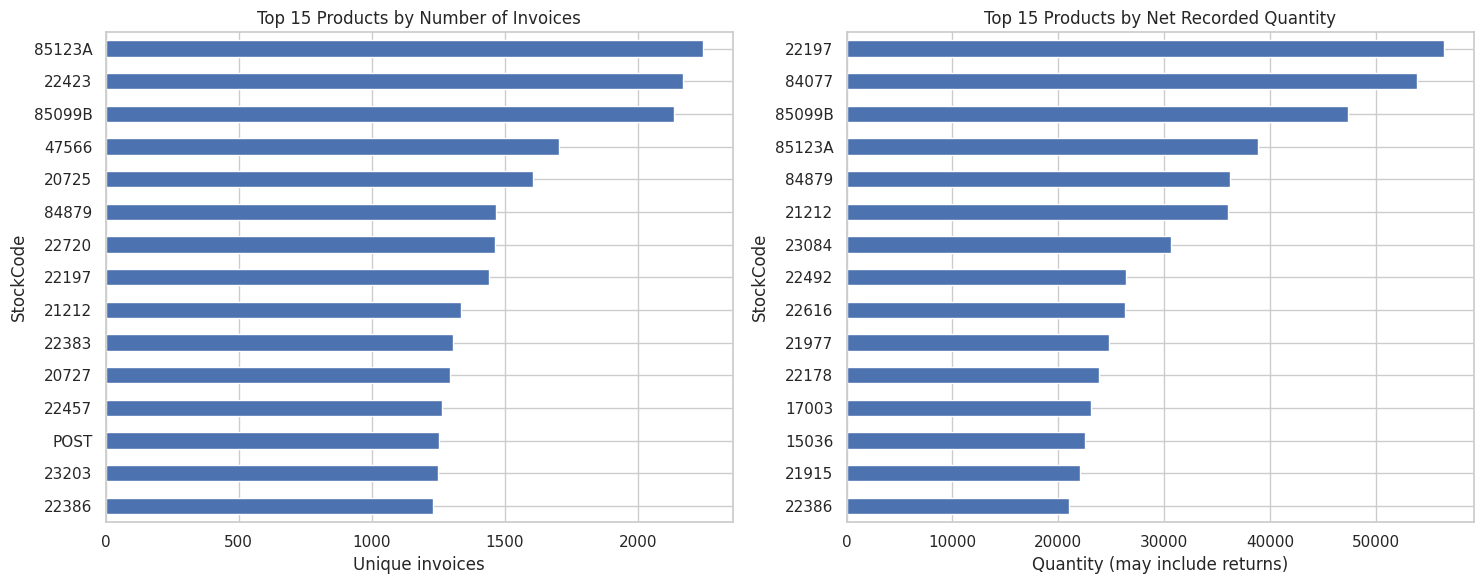

Top products by invoice count:


,invoice_count
StockCode,
85123A,2246
22423,2172
85099B,2135
47566,1706
20725,1608
84879,1468
22720,1462
22197,1442
21212,1334


Top products by net recorded quantity:


,net_quantity
StockCode,
22197,56450
84077,53847
85099B,47363
85123A,38830
84879,36221
21212,36039
23084,30646
22492,26437
22616,26315


Unique invoice IDs: 25900
Unique stock codes: 4070
Unique non-missing customer IDs: 4372


In [11]:
# Only rows with identifiable invoice and product IDs for these exploratory counts.
identifiable = df.dropna(subset=["InvoiceNo", "StockCode"]).copy()

product_invoice_counts = (
    identifiable.groupby("StockCode")["InvoiceNo"].nunique()
    .sort_values(ascending=False)
)
product_quantity = (
    identifiable.groupby("StockCode")["Quantity"].sum(min_count=1)
    .sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
product_invoice_counts.head(15).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 15 Products by Number of Invoices")
axes[0].set_xlabel("Unique invoices")
product_quantity.head(15).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 15 Products by Net Recorded Quantity")
axes[1].set_xlabel("Quantity (may include returns)")
plt.tight_layout()
plt.show()

print("Top products by invoice count:")
display(product_invoice_counts.head(15).rename("invoice_count").to_frame())
print("Top products by net recorded quantity:")
display(product_quantity.head(15).rename("net_quantity").to_frame())

print("Unique invoice IDs:", identifiable["InvoiceNo"].nunique())
print("Unique stock codes:", identifiable["StockCode"].nunique())
print("Unique non-missing customer IDs:", df["CustomerID"].nunique(dropna=True))

## 10. EDA: basket size

Basket size means the number of distinct products in an invoice. An invoice with one product cannot directly provide evidence that two different products were bought together.

,distinct_products
count,"25,900.000"
mean,20.511
std,42.500
min,1.000
50%,10.000
75%,23.000
90%,45.000
95%,66.000
99%,191.000
max,"1,110.000"


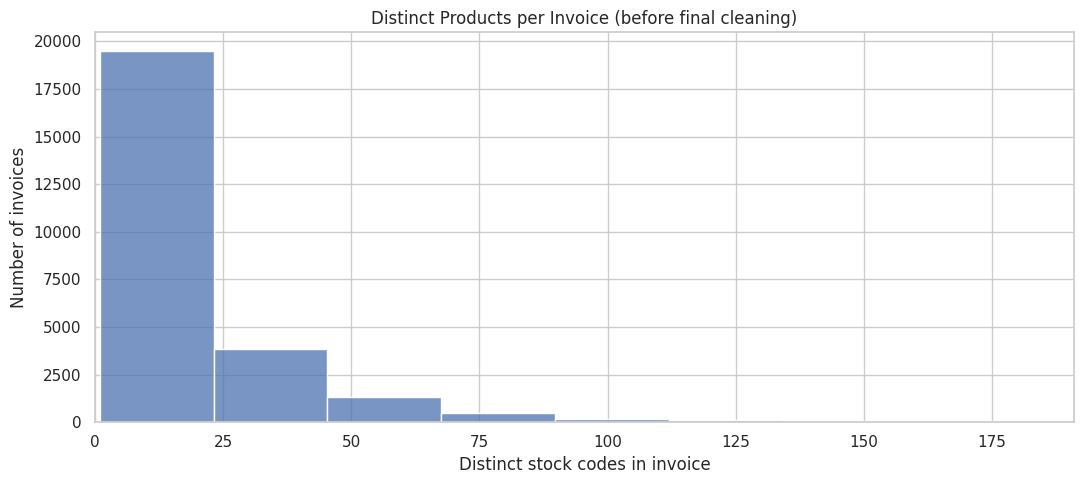

Invoices with only one distinct product: 5894
Invoices with two or more distinct products: 20006


In [12]:
invoice_product_counts = (
    identifiable.groupby("InvoiceNo")["StockCode"].nunique()
    .rename("distinct_products")
)

display(invoice_product_counts.describe(percentiles=[.5, .75, .9, .95, .99]))

plt.figure(figsize=(11, 5))
sns.histplot(invoice_product_counts, bins=50)
plt.title("Distinct Products per Invoice (before final cleaning)")
plt.xlabel("Distinct stock codes in invoice")
plt.ylabel("Number of invoices")
plt.xlim(0, invoice_product_counts.quantile(0.99))
plt.tight_layout()
plt.show()

print("Invoices with only one distinct product:",
      int((invoice_product_counts == 1).sum()))
print("Invoices with two or more distinct products:",
      int((invoice_product_counts >= 2).sum()))

## 11. EDA: time patterns

We explore invoice volume over time. These charts are useful for understanding seasonality and for choosing a chronological evaluation split later. Invalid dates are excluded from this time-based chart.

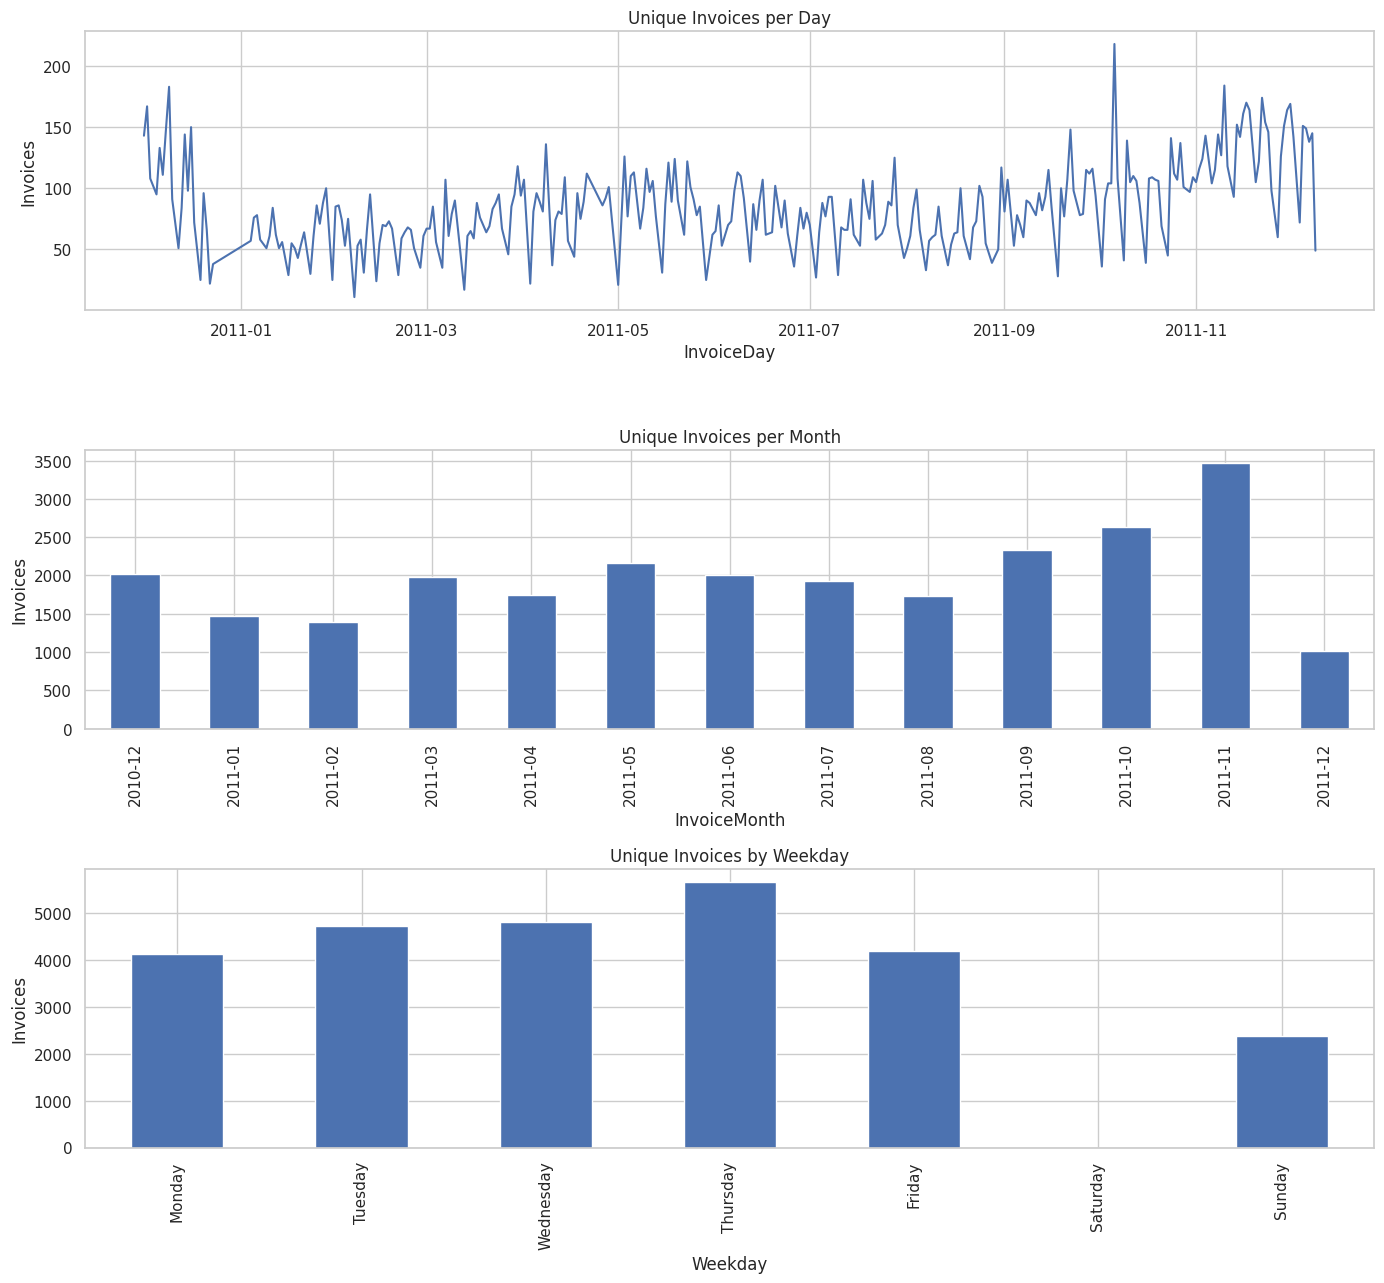

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [13]:
time_df = df.dropna(subset=["InvoiceDate", "InvoiceNo"]).copy()
time_df["InvoiceDay"] = time_df["InvoiceDate"].dt.date
time_df["InvoiceMonth"] = time_df["InvoiceDate"].dt.to_period("M").astype(str)
time_df["Weekday"] = time_df["InvoiceDate"].dt.day_name()

daily_invoices = time_df.groupby("InvoiceDay")["InvoiceNo"].nunique()
monthly_invoices = time_df.groupby("InvoiceMonth")["InvoiceNo"].nunique()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_invoices = (
    time_df.groupby("Weekday")["InvoiceNo"].nunique()
    .reindex(weekday_order)
)

fig, axes = plt.subplots(3, 1, figsize=(14, 13))
daily_invoices.plot(ax=axes[0])
axes[0].set_title("Unique Invoices per Day")
axes[0].set_ylabel("Invoices")
monthly_invoices.plot(kind="bar", ax=axes[1])
axes[1].set_title("Unique Invoices per Month")
axes[1].set_ylabel("Invoices")
weekday_invoices.plot(kind="bar", ax=axes[2])
axes[2].set_title("Unique Invoices by Weekday")
axes[2].set_ylabel("Invoices")
plt.tight_layout()
plt.show()

print("Date range:", time_df["InvoiceDate"].min(), "to", time_df["InvoiceDate"].max())

## 12. EDA: geography and customer data

Country and customer fields are useful for understanding data coverage and possible future segmentation. They are not required features for the baseline basket matrix.

,unique_invoices
Country,
United Kingdom,23494
Germany,603
France,461
EIRE,360
Belgium,119
Spain,105
Netherlands,101
Switzerland,74
Portugal,71


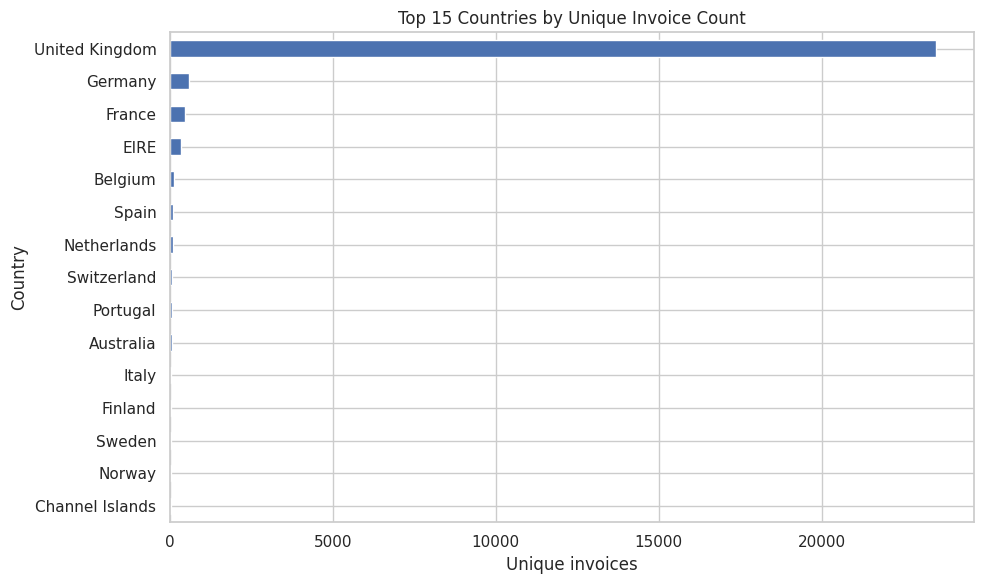

Rows with CustomerID: 406,829 / 541,909 (75.1%)
Unique customers with IDs: 4372


In [14]:
if df["Country"].notna().any():
    country_summary = (
        df.dropna(subset=["Country", "InvoiceNo"])
          .groupby("Country")["InvoiceNo"].nunique()
          .sort_values(ascending=False)
    )
    display(country_summary.head(15).rename("unique_invoices").to_frame())
    country_summary.head(15).sort_values().plot(kind="barh", figsize=(10, 6))
    plt.title("Top 15 Countries by Unique Invoice Count")
    plt.xlabel("Unique invoices")
    plt.tight_layout()
    plt.show()

customer_id_present = df["CustomerID"].notna().sum()
print(f"Rows with CustomerID: {customer_id_present:,} / {len(df):,} ({customer_id_present / max(len(df), 1):.1%})")
print("Unique customers with IDs:", df["CustomerID"].nunique(dropna=True))

## 13. Define the cleaning policy

The next cell applies a transparent baseline for **positive-purchase basket mining**:

1. Remove exact duplicate rows.
2. Exclude invoice IDs beginning with `C`.
3. Require invoice ID, product ID, valid date, quantity and unit price.
4. Keep only positive quantities and positive prices.
5. Preserve rows with missing customer IDs.
6. Preserve product IDs even if descriptions are missing.

This policy intentionally excludes returns and zero-price lines from the baseline baskets. That is a modelling decision; keep the original data for separate return analysis. Review the audit output before using the cleaned data for model training.

In [15]:
clean = df_raw.copy(deep=True)
clean.columns = [str(c).strip() for c in clean.columns]

column_map = {}
for col in clean.columns:
    key = col.strip().lower().replace(" ", "").replace("_", "")
    aliases = {
        "invoiceno": "InvoiceNo", "stockcode": "StockCode",
        "description": "Description", "quantity": "Quantity",
        "invoicedate": "InvoiceDate", "unitprice": "UnitPrice",
        "customerid": "CustomerID", "country": "Country"
    }
    if key in aliases:
        column_map[col] = aliases[key]
clean = clean.rename(columns=column_map)

for optional_col in ["Description", "CustomerID", "Country"]:
    if optional_col not in clean.columns:
        clean[optional_col] = pd.NA

clean["InvoiceNo"] = clean["InvoiceNo"].astype("string").str.strip()
clean["StockCode"] = clean["StockCode"].astype("string").str.strip()
clean["Description"] = clean["Description"].astype("string").str.strip()
clean["Country"] = clean["Country"].astype("string").str.strip()
clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"], errors="coerce")
clean["Quantity"] = pd.to_numeric(clean["Quantity"], errors="coerce")
clean["UnitPrice"] = pd.to_numeric(clean["UnitPrice"], errors="coerce")

audit = []
audit.append({"stage": "Raw input", "rows_remaining": len(clean), "rows_removed_at_stage": 0})

before = len(clean)
clean = clean.drop_duplicates().copy()
audit.append({"stage": "Remove exact duplicate rows", "rows_remaining": len(clean), "rows_removed_at_stage": before-len(clean)})

before = len(clean)
cancel_mask = clean["InvoiceNo"].str.upper().str.startswith("C", na=False)
clean = clean.loc[~cancel_mask].copy()
audit.append({"stage": "Exclude cancellation invoices (C prefix)", "rows_remaining": len(clean), "rows_removed_at_stage": before-len(clean)})

before = len(clean)
clean = clean.dropna(subset=["InvoiceNo", "StockCode", "InvoiceDate", "Quantity", "UnitPrice"]).copy()
clean = clean.loc[
    (clean["InvoiceNo"].str.len() > 0) &
    (clean["StockCode"].str.len() > 0)
].copy()
audit.append({"stage": "Require transaction/product/date/quantity/price", "rows_remaining": len(clean), "rows_removed_at_stage": before-len(clean)})

before = len(clean)
clean = clean.loc[clean["Quantity"] > 0].copy()
audit.append({"stage": "Keep positive quantities", "rows_remaining": len(clean), "rows_removed_at_stage": before-len(clean)})

before = len(clean)
clean = clean.loc[clean["UnitPrice"] > 0].copy()
audit.append({"stage": "Keep positive unit prices", "rows_remaining": len(clean), "rows_removed_at_stage": before-len(clean)})

clean["LineRevenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["InvoiceMonth"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["InvoiceDay"] = clean["InvoiceDate"].dt.date

cleaning_audit = pd.DataFrame(audit)
display(cleaning_audit)
print(f"Raw rows: {len(df_raw):,}")
print(f"Cleaned purchase rows: {len(clean):,}")
print(f"Retained: {len(clean)/max(len(df_raw),1):.1%}")
print(f"Unique invoices after cleaning: {clean['InvoiceNo'].nunique():,}")
print(f"Unique products after cleaning: {clean['StockCode'].nunique():,}")

,stage,rows_remaining,rows_removed_at_stage
0,Raw input,541909,0
1,Remove exact duplicate rows,536641,5268
2,Exclude cancellation invoices (C prefix),527390,9251
3,Require transaction/product/date/quantity/price,527390,0
4,Keep positive quantities,526054,1336
5,Keep positive unit prices,524878,1176


Raw rows: 541,909
Cleaned purchase rows: 524,878
Retained: 96.9%
Unique invoices after cleaning: 19,960
Unique products after cleaning: 3,922


## 14. Validate the cleaned dataset

Cleaning is not complete until we verify that the output satisfies the assumptions needed by the model.

In [16]:
validation = {
    "no missing InvoiceNo": int(clean["InvoiceNo"].isna().sum()) == 0,
    "no missing StockCode": int(clean["StockCode"].isna().sum()) == 0,
    "no missing InvoiceDate": int(clean["InvoiceDate"].isna().sum()) == 0,
    "all quantities positive": bool((clean["Quantity"] > 0).all()),
    "all unit prices positive": bool((clean["UnitPrice"] > 0).all()),
    "no cancellation invoice IDs": bool(
        ~clean["InvoiceNo"].str.upper().str.startswith("C", na=False).any()
    ),
    "no exact duplicate rows": int(clean.duplicated().sum()) == 0,
    "LineRevenue matches Quantity x UnitPrice": bool(
        np.allclose(clean["LineRevenue"], clean["Quantity"] * clean["UnitPrice"])
    )
}
validation_table = pd.DataFrame({
    "Check": list(validation.keys()),
    "Passed": list(validation.values())
})
display(validation_table)

if not all(validation.values()):
    print("WARNING: One or more checks failed. Inspect the data before model training.")
else:
    print("All baseline validation checks passed.")

,Check,Passed
0,no missing InvoiceNo,True
1,no missing StockCode,True
2,no missing InvoiceDate,True
3,all quantities positive,True
4,all unit prices positive,True
5,no cancellation invoice IDs,True
6,no exact duplicate rows,True
7,LineRevenue matches Quantity x UnitPrice,True


All baseline validation checks passed.


## 15. Feature engineering: create a product lookup table

`StockCode` remains the canonical identifier. `Description` is for display. If a code has multiple descriptions, the most common non-missing description is selected for display.

In [17]:
description_rows = clean.dropna(subset=["StockCode", "Description"]).copy()
description_rows = description_rows[
    description_rows["Description"].str.strip().ne("")
]

def most_common_description(series):
    modes = series.mode()
    if not modes.empty:
        return modes.iloc[0]
    return series.iloc[0] if len(series) else "Unknown product"

product_lookup_df = (
    description_rows.groupby("StockCode")["Description"]
    .agg(most_common_description)
    .rename("ProductName")
    .reset_index()
)

# Include any product codes without a usable description.
all_products = pd.DataFrame({"StockCode": clean["StockCode"].dropna().unique()})
product_lookup_df = all_products.merge(product_lookup_df, on="StockCode", how="left")
product_lookup_df["ProductName"] = product_lookup_df["ProductName"].fillna("Unknown product")

display(product_lookup_df.head(15))
print("Products with unknown display name:",
      int((product_lookup_df["ProductName"] == "Unknown product").sum()))

,StockCode,ProductName
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER
1,71053,WHITE METAL LANTERN
2,84406B,CREAM CUPID HEARTS COAT HANGER
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE
4,84029E,RED WOOLLY HOTTIE WHITE HEART.
5,22752,SET 7 BABUSHKA NESTING BOXES
6,21730,GLASS STAR FROSTED T-LIGHT HOLDER
7,22633,HAND WARMER UNION JACK
8,22632,HAND WARMER RED RETROSPOT
9,84879,ASSORTED COLOUR BIRD ORNAMENT


Products with unknown display name: 0


## 16. Feature engineering: aggregate invoice-product lines

First combine repeated rows for the same invoice and product. Then convert the quantity into presence/absence. For the baseline Apriori model, ten units of a product still count as one product present in that invoice.

In [18]:
invoice_product = (
    clean.groupby(["InvoiceNo", "StockCode"], as_index=False)
         .agg(
             Quantity=("Quantity", "sum"),
             LineRevenue=("LineRevenue", "sum"),
             InvoiceDate=("InvoiceDate", "min")
         )
)

invoice_product["Present"] = invoice_product["Quantity"] > 0

print("Cleaned product-line rows:", len(clean))
print("Unique invoice-product pairs:", len(invoice_product))
print("Duplicate invoice-product pairs remaining:",
      int(invoice_product.duplicated(["InvoiceNo", "StockCode"]).sum()))

display(invoice_product.head(10))

Cleaned product-line rows: 524878
Unique invoice-product pairs: 519602
Duplicate invoice-product pairs remaining: 0


,InvoiceNo,StockCode,Quantity,LineRevenue,InvoiceDate,Present
0,536365,21730,6,25.500,2010-12-01 08:26:00,True
1,536365,22752,2,15.300,2010-12-01 08:26:00,True
2,536365,71053,6,20.340,2010-12-01 08:26:00,True
3,536365,84029E,6,20.340,2010-12-01 08:26:00,True
4,536365,84029G,6,20.340,2010-12-01 08:26:00,True
5,536365,84406B,8,22.000,2010-12-01 08:26:00,True
6,536365,85123A,6,15.300,2010-12-01 08:26:00,True
7,536366,22632,6,11.100,2010-12-01 08:28:00,True
8,536366,22633,6,11.100,2010-12-01 08:28:00,True
9,536367,21754,3,17.850,2010-12-01 08:34:00,True


## 17. Feature engineering: build the binary basket matrix

Rows are invoices. Columns are products. `True` means the product appears in the invoice. This is the input format for Apriori.

In [19]:
basket = (
    invoice_product.pivot_table(
        index="InvoiceNo",
        columns="StockCode",
        values="Present",
        aggfunc="max",
        fill_value=False
    )
    .astype(bool)
)

# Ensure every value is boolean and there are no empty invoice rows.
empty_baskets = int((basket.sum(axis=1) == 0).sum())
basket = basket.loc[basket.sum(axis=1) > 0].copy()

print("Basket matrix shape:", basket.shape)
print("Invoices:", basket.shape[0])
print("Products:", basket.shape[1])
print("Empty baskets removed:", empty_baskets)
print("Matrix density:", f"{basket.to_numpy().mean():.4%}")
display(basket.iloc[:10, :min(12, basket.shape[1])])

Basket matrix shape: (19960, 3922)
Invoices: 19960
Products: 3922
Empty baskets removed: 0
Matrix density: 0.6637%


StockCode,10002,10080,10120,10123C,10124A,10124G,10125,10133,10135,11001,15030,15034
InvoiceNo,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,False,False
536370,True,False,False,False,False,False,False,False,False,False,False,False
536371,False,False,False,False,False,False,False,False,False,False,False,False
536372,False,False,False,False,False,False,False,False,False,False,False,False
536373,False,False,False,False,False,False,False,False,False,False,False,False


## 18. Understand the final baskets

The next charts show the number of distinct products per invoice and how often products occur. These are more directly relevant to association mining than raw unit counts.

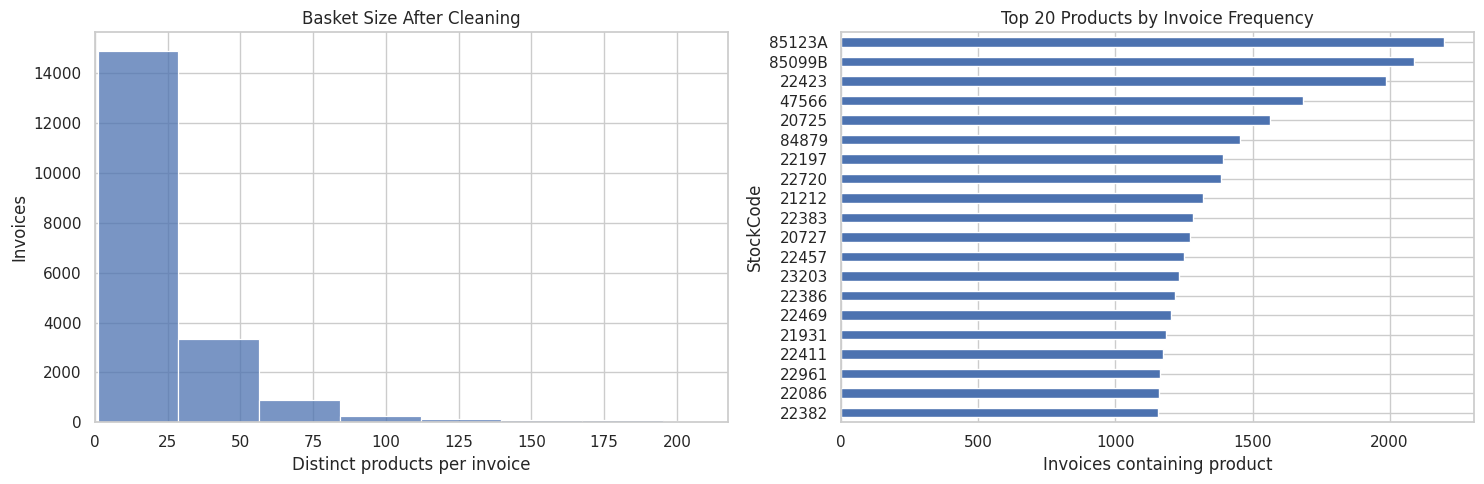

Basket size summary:


,products_per_invoice
count,"19,960.000"
mean,26.032
std,46.982
min,1.000
50%,15.000
75%,29.000
90%,52.000
95%,75.000
99%,217.410
max,"1,110.000"


Single-product baskets: 1641
Multi-product baskets: 18319


In [20]:
basket_sizes = basket.sum(axis=1)
product_invoice_frequency = basket.sum(axis=0).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(basket_sizes, bins=40, ax=axes[0])
axes[0].set_title("Basket Size After Cleaning")
axes[0].set_xlabel("Distinct products per invoice")
axes[0].set_ylabel("Invoices")
axes[0].set_xlim(0, basket_sizes.quantile(0.99))

product_invoice_frequency.head(20).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 20 Products by Invoice Frequency")
axes[1].set_xlabel("Invoices containing product")
plt.tight_layout()
plt.show()

print("Basket size summary:")
display(basket_sizes.describe(percentiles=[.5, .75, .9, .95, .99]).to_frame("products_per_invoice"))
print("Single-product baskets:", int((basket_sizes == 1).sum()))
print("Multi-product baskets:", int((basket_sizes >= 2).sum()))

## 19. Check product sparsity and possible filtering

Apriori can become slow when there are many products and combinations. First measure product frequency. Do not filter rare products without recording the reason, because a rare product could still have a meaningful association.

,support,invoice_count,product_name
StockCode,,,
85123A,0.110,2198,WHITE HANGING HEART T-LIGHT HOLDER
85099B,0.105,2089,JUMBO BAG RED RETROSPOT
22423,0.100,1988,REGENCY CAKESTAND 3 TIER
47566,0.084,1685,PARTY BUNTING
20725,0.078,1565,LUNCH BAG RED RETROSPOT
84879,0.073,1455,ASSORTED COLOUR BIRD ORNAMENT
22197,0.070,1392,POPCORN HOLDER
22720,0.069,1385,SET OF 3 CAKE TINS PANTRY DESIGN
21212,0.066,1320,PACK OF 72 RETROSPOT CAKE CASES


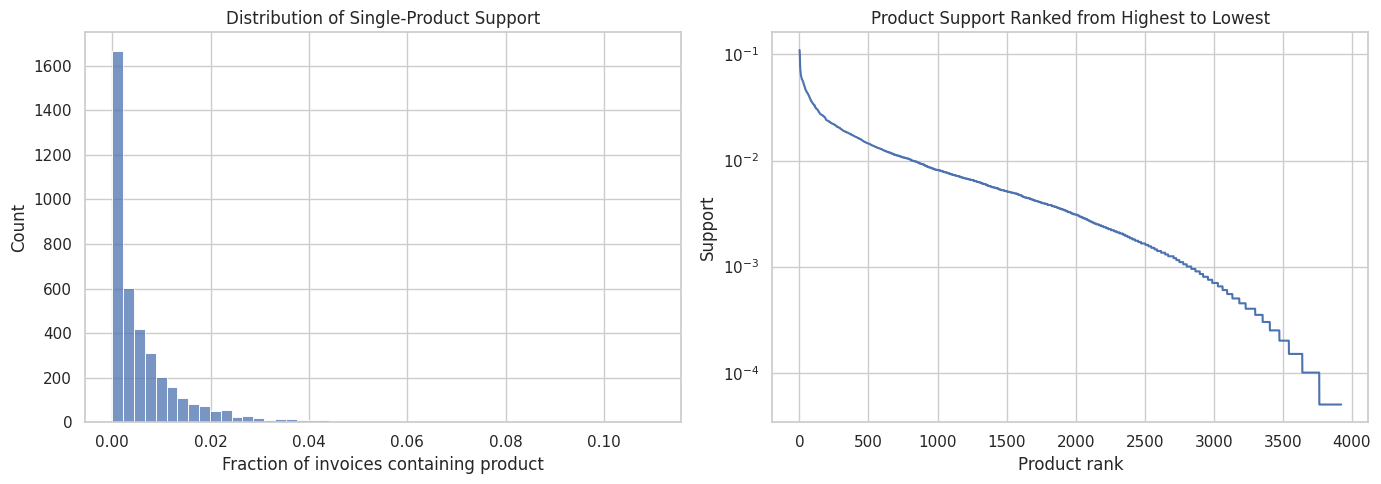

Products appearing in only 1 invoice: 159
Products appearing in fewer than 5 invoices: 448


In [21]:
n_invoices = basket.shape[0]
product_support = basket.mean(axis=0).sort_values(ascending=False)
product_support_df = product_support.rename("support").to_frame()
product_support_df["invoice_count"] = basket.sum(axis=0)
product_support_df["product_name"] = product_support_df.index.map(
    product_lookup_df.set_index("StockCode")["ProductName"].to_dict()
)

display(product_support_df.head(20))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(product_support.values, bins=50, ax=axes[0])
axes[0].set_title("Distribution of Single-Product Support")
axes[0].set_xlabel("Fraction of invoices containing product")
axes[1].plot(np.arange(1, len(product_support)+1), product_support.values)
axes[1].set_title("Product Support Ranked from Highest to Lowest")
axes[1].set_xlabel("Product rank")
axes[1].set_ylabel("Support")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

print("Products appearing in only 1 invoice:", int((basket.sum(axis=0) == 1).sum()))
print("Products appearing in fewer than 5 invoices:", int((basket.sum(axis=0) < 5).sum()))

## 20. Optional experiment: filter very rare products

This section creates an **experimental** basket matrix containing products appearing in at least a chosen number of invoices. It does not replace the full basket matrix.

Start with `MIN_PRODUCT_INVOICES = 5` as a computational experiment only. Compare model coverage and rule results before deciding whether this filter belongs in the final pipeline.

In [22]:
MIN_PRODUCT_INVOICES = 5

product_counts = basket.sum(axis=0)
eligible_products = product_counts[product_counts >= MIN_PRODUCT_INVOICES].index
basket_filtered = basket.loc[:, eligible_products].copy()

print("Original matrix:", basket.shape)
print("Filtered matrix:", basket_filtered.shape)
print("Products removed:", basket.shape[1] - basket_filtered.shape[1])
print("Share of products retained:", f"{basket_filtered.shape[1]/max(basket.shape[1],1):.1%}")
print("Share of invoice-product presences retained:",
      f"{basket_filtered.to_numpy().sum()/max(basket.to_numpy().sum(),1):.1%}")

display(pd.DataFrame({
    "Version": ["Full basket", f"At least {MIN_PRODUCT_INVOICES} invoices"],
    "Invoices": [basket.shape[0], basket_filtered.shape[0]],
    "Products": [basket.shape[1], basket_filtered.shape[1]],
    "Presence cells": [int(basket.to_numpy().sum()), int(basket_filtered.to_numpy().sum())]
}))

Original matrix: (19960, 3922)
Filtered matrix: (19960, 3474)
Products removed: 448
Share of products retained: 88.6%
Share of invoice-product presences retained: 99.8%


,Version,Invoices,Products,Presence cells
0,Full basket,19960,3922,519602
1,At least 5 invoices,19960,3474,518630


## 21. Optional customer and country features for future segmentation

The baseline Apriori model does not require these features. They are retained for business analysis and the PRD's future new-vs-repeat customer cohort stretch goal.

A customer with multiple invoices can be classified as repeat in this dataset. Be cautious: a missing customer ID cannot be reliably assigned to a new or repeat cohort.

In [23]:
customer_invoice_counts = (
    clean.dropna(subset=["CustomerID", "InvoiceNo"])
         .groupby("CustomerID")["InvoiceNo"].nunique()
)

customer_cohort = pd.DataFrame({
    "CustomerID": customer_invoice_counts.index,
    "invoice_count": customer_invoice_counts.values
})
customer_cohort["cohort"] = np.where(
    customer_cohort["invoice_count"] >= 2,
    "Repeat (2+ invoices in dataset)",
    "One invoice in dataset"
)

display(customer_cohort["cohort"].value_counts().to_frame("customers"))

if clean["Country"].notna().any():
    country_revenue = (
        clean.dropna(subset=["Country"])
             .groupby("Country")["LineRevenue"].sum()
             .sort_values(ascending=False)
    )
    display(country_revenue.head(15).rename("recorded_line_revenue").to_frame())

,customers
cohort,
Repeat (2+ invoices in dataset),2845
One invoice in dataset,1493


,recorded_line_revenue
Country,
United Kingdom,"9,001,744.094"
Netherlands,"285,446.340"
EIRE,"283,140.520"
Germany,"228,678.400"
France,"209,625.370"
Australia,"138,453.810"
Spain,"61,558.560"
Switzerland,"57,067.600"
Belgium,"41,196.340"
